# Imports 

In [3]:
import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, StratifiedShuffleSplit, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler, MinMaxScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from skopt import BayesSearchCV
from sklearn.metrics import confusion_matrix
import joblib
from sklvq import GLVQ
import matplotlib.pyplot as plt
from sklearn.ensemble import AdaBoostClassifier

random_state=42

-----

# Functions

In [4]:
def train_validation_test_split(
        X, y, validation_size=0.1,
        test_size=0.1, random_state=42):
    
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y
    )

    X_train, X_valid, y_train, y_valid = train_test_split(
        X_train, y_train,
        test_size=validation_size / (1 - test_size),
        random_state=random_state,
        stratify=y_train,
    )
    return X_train, X_valid, X_test, y_train, y_valid, y_test

In [29]:
from scipy import stats
def confidence_interval(data, confidence=0.95):
    mean = np.mean(data)
    n = len(data)
    std_err = np.std(data, ddof=1) / np.sqrt(n)
    t_value = stats.t.ppf((1 + confidence) / 2, n - 1)
    margin_of_error = t_value * std_err

    return f"{mean:.5f} ± {margin_of_error:.5f}"

In [1]:
def report_model_performance(model, X_train, X_valid, X_test, y_train, y_valid, y_test):
    
    accuracy_best_param_cv = np.array([model.steps[-1][-1].cv_results_[f"split{i}_test_Accuracy"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    precision_best_param_cv = np.array([model.steps[-1][-1].cv_results_[f"split{i}_test_Precision"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    recall_best_param_cv = np.array([model.steps[-1][-1].cv_results_[f"split{i}_test_Recall"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    f1_best_param_cv = np.array([model.steps[-1][-1].cv_results_[f"split{i}_test_F1"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    roc_best_param_cv = np.array([model.steps[-1][-1].cv_results_[f"split{i}_test_ROC-AUC"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]

    best_param = model.steps[-1][-1].best_params_
    print(f"Best parameters: {best_param}")
    print(f"Cross Validation accuracy Array: {accuracy_best_param_cv}")
    print(f"Validation accuracy: {confidence_interval(accuracy_best_param_cv)}")
    
    print(f"Cross Validation precision Array: {precision_best_param_cv}")
    print(f"Validation precision: {confidence_interval(precision_best_param_cv)}")
    
    print(f"Cross Validation recall Array: {recall_best_param_cv}")
    print(f"Validation recall: {confidence_interval(recall_best_param_cv)}")
    
    print(f"Cross Validation f1 Array: {f1_best_param_cv}")
    print(f"Validation f1: {confidence_interval(f1_best_param_cv)}")
    
    print(f"Cross Validation roc Array: {roc_best_param_cv}")
    print(f"Validation roc: {confidence_interval(roc_best_param_cv)}")
    
    print()
    y_train_pred = model.predict(X_train)
    y_valid_pred = model.predict(X_valid)
    y_test_pred = model.predict(X_test)
    
    y_train_proba = model.predict_proba(X_train)
    y_valid_proba = model.predict_proba(X_valid)
    y_test_proba = model.predict_proba(X_test)
    print("===> Training performance")
    print(classification_report(y_train, y_train_pred, digits=5))
    print(f"Train ROC-AUC: {roc_auc_score(y_train, y_train_proba, multi_class='ovr'):.3f}")
    print("===> Validation performance")
    print(classification_report(y_valid, y_valid_pred, digits=5))
    print(f"Validation ROC-AUC: {roc_auc_score(y_valid, y_valid_proba, multi_class='ovr'):.3f}")
    print("===> Test performance")
    print(classification_report(y_test, y_test_pred, digits=5))
    print(f"Test ROC-AUC: {roc_auc_score(y_test, y_test_proba, multi_class='ovr'):.3f}")
    
    with sns.plotting_context("notebook", font_scale=1.5):
        conf_matrix = confusion_matrix(y_train, y_train_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title("Train Confusion Matrix")
        plt.show()

    with sns.plotting_context("notebook", font_scale=1.5):
        conf_matrix = confusion_matrix(y_valid, y_valid_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title("Validation Confusion Matrix")
        plt.show()
        
    with sns.plotting_context("notebook", font_scale=1.5):
        conf_matrix = confusion_matrix(y_test, y_test_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title("Test Confusion Matrix")
        plt.show()

In [6]:
def save_model(model, model_name):
    joblib.dump(model, f"{model_name}.joblib")

# Read Dataset

In [97]:
wine_quality  = fetch_ucirepo(id=186)

X = wine_quality.data.features
y = wine_quality.data.targets

# Descritive statistics

In [98]:
X.describe()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000


In [99]:
y["quality"].value_counts(normalize=True)

quality
6    0.436509
5    0.329075
7    0.166077
4    0.033246
8    0.029706
3    0.004618
9    0.000770
Name: proportion, dtype: float64

<Axes: >

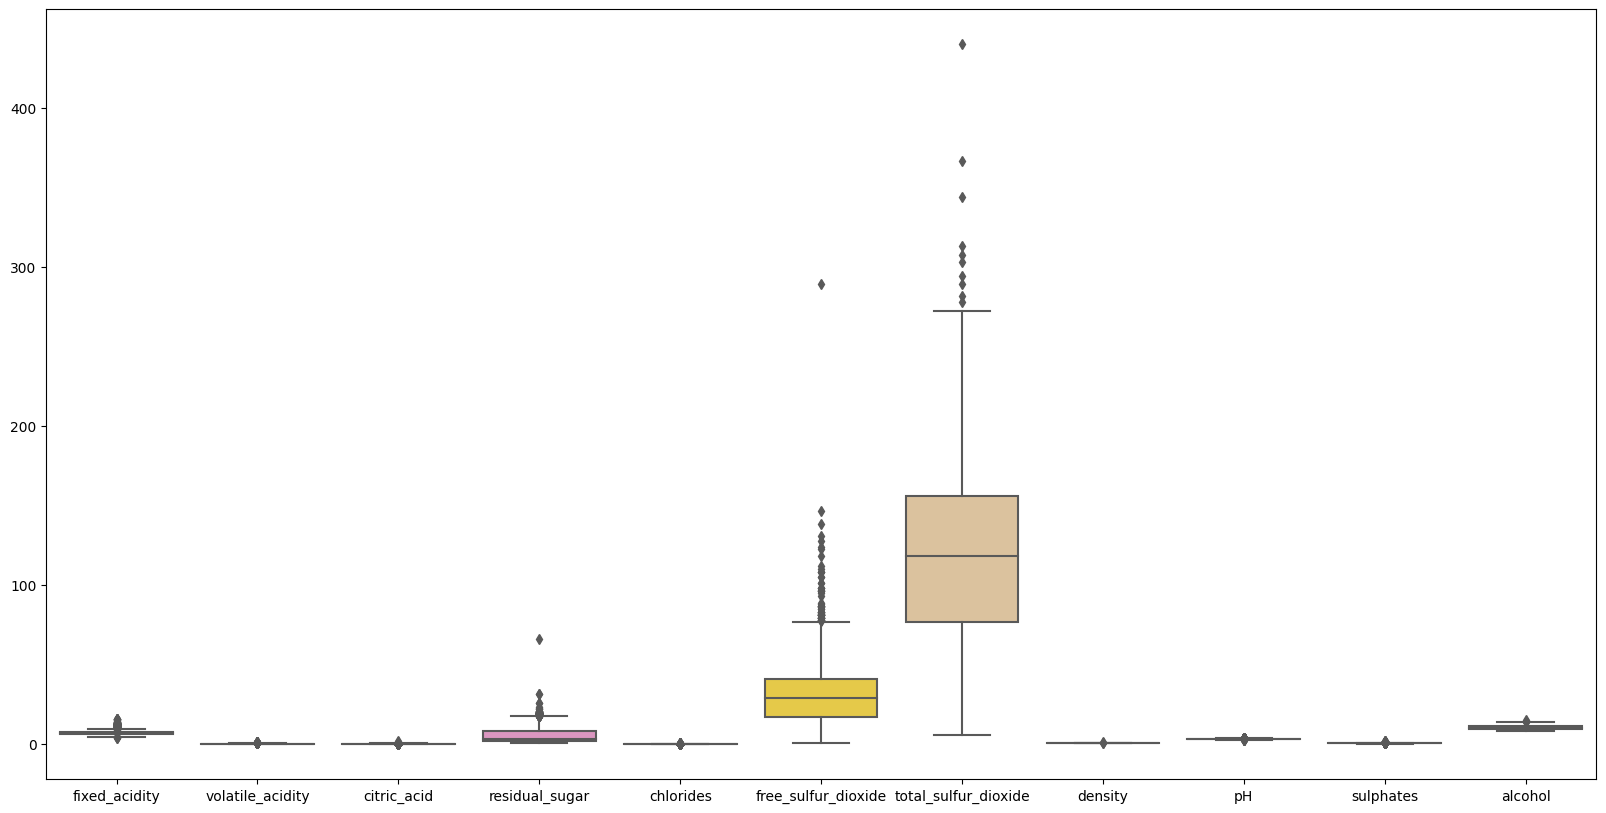

In [100]:
plt.figure(figsize=(20,10))
sns.boxplot(X, palette="Set2",)

## Split Dataset

In [101]:
X_train, X_valid, X_test, y_train, y_valid, y_test = train_validation_test_split(
    X, y, validation_size=0.15, test_size=0.15, random_state=random_state
)

In [102]:
X_train.shape, X_valid.shape, X_test.shape


((4547, 11), (975, 11), (975, 11))

In [103]:
y_train.shape, y_valid.shape, y_test.shape

((4547, 1), (975, 1), (975, 1))

In [104]:
y_train.value_counts(), y_valid.value_counts(), y_test.value_counts()

(quality
 6          1985
 5          1496
 7           755
 4           152
 8           135
 3            21
 9             3
 Name: count, dtype: int64,
 quality
 6          425
 5          321
 7          162
 4           32
 8           29
 3            5
 9            1
 Name: count, dtype: int64,
 quality
 6          426
 5          321
 7          162
 4           32
 8           29
 3            4
 9            1
 Name: count, dtype: int64)

# Pre-processing

## Scaling the data

In [105]:
scaler_knn = MinMaxScaler()
scaler_lvq = MinMaxScaler()
scaler_dt = MinMaxScaler()
scaler_rf = MinMaxScaler()
scaler_ada = MinMaxScaler()
scaler_mlp = MinMaxScaler()

# Model

## KNN 

In [109]:
cv = StratifiedShuffleSplit(n_splits=50, test_size=0.2, random_state=random_state)
knn = KNeighborsClassifier()
scoring = {
    "Accuracy": "accuracy", "ROC-AUC": "roc_auc_ovr",
    "Precision": "precision_macro", "Recall": "recall_macro", "F1": "f1_macro",
}
knn_opt = BayesSearchCV(
    knn,
    {
        "n_neighbors": (1, 80),
        "weights": ["uniform", "distance"],
        "p": (1, 2, 3, 4, 5),
    },
    n_iter=25,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_knn = Pipeline([("scaler", scaler_knn), ("knn", knn_opt)])

In [110]:
pipe_knn.fit(X_train, y_train["quality"])

Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits


c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\skopt\optimizer\optimizer.py:517: UserWarning: The objective has been evaluated at point [80, 1, 'distance'] before, using random point [32, 1, 'uniform']
  warnings.warn(


Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits


c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\skopt\optimizer\optimizer.py:517: UserWarning: The objective has been evaluated at point [80, 1, 'distance'] before, using random point [7, 2, 'distance']
  warnings.warn(


Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits


Pipeline(steps=[('scaler', MinMaxScaler()),
                ('knn',
                 BayesSearchCV(cv=StratifiedShuffleSplit(n_splits=50, random_state=42, test_size=0.2,
            train_size=None),
                               estimator=KNeighborsClassifier(), n_iter=25,
                               n_jobs=-1, random_state=42, refit='Accuracy',
                               scoring={'Accuracy': 'accuracy',
                                        'F1': 'f1_macro',
                                        'Precision': 'precision_macro',
                                        'ROC-AUC': 'roc_auc_ovr',
                                        'Recall': 'recall_macro'},
                               search_spaces={'n_neighbors': (1, 80),
                                              'p': (1, 2, 3, 4, 5),
                                              'weights': ['uniform',
                                                          'distance']},
                               verbose=1))])

Best parameters: OrderedDict([('n_neighbors', 70), ('p', 1), ('weights', 'distance')])
Cross Validation accuracy Array: [0.65494505 0.63956044 0.65054945 0.66153846 0.65934066 0.64065934
 0.66923077 0.63406593 0.67362637 0.65934066 0.64395604 0.63626374
 0.64615385 0.65604396 0.65714286 0.63736264 0.64285714 0.62087912
 0.65824176 0.66153846 0.64175824 0.65054945 0.64615385 0.67142857
 0.66813187 0.62527473 0.64065934 0.65384615 0.65164835 0.64175824
 0.64175824 0.63956044 0.63736264 0.64065934 0.63736264 0.61978022
 0.67252747 0.65274725 0.65934066 0.65054945 0.64945055 0.62747253
 0.65714286 0.64065934 0.65054945 0.63846154 0.65824176 0.66703297
 0.65604396 0.62417582]
Validation accuracy: 0.64831 ± 0.00380
Cross Validation precision Array: [0.56795829 0.56085902 0.57415583 0.57404272 0.57238027 0.55918606
 0.58886451 0.55426137 0.58077721 0.57869871 0.56171748 0.56088094
 0.56030381 0.56314849 0.56588765 0.56152883 0.56399666 0.5560975
 0.56822518 0.57452653 0.56422524 0.56332127 0.

c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` param

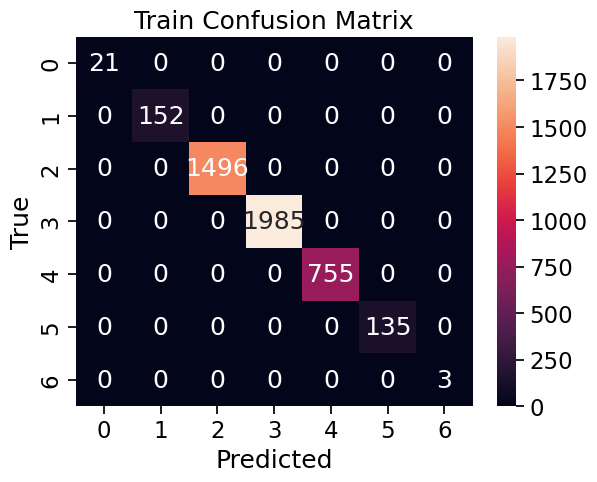

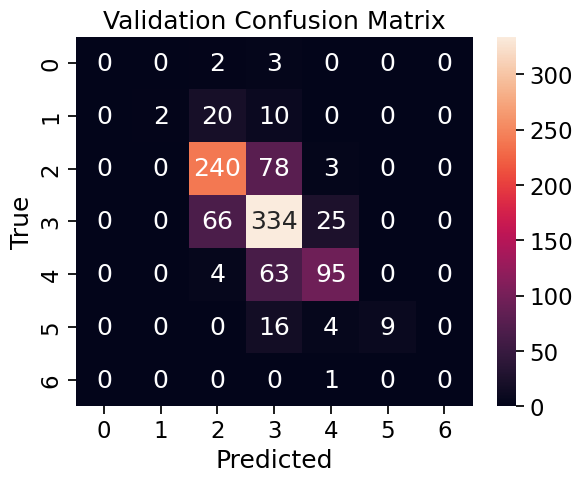

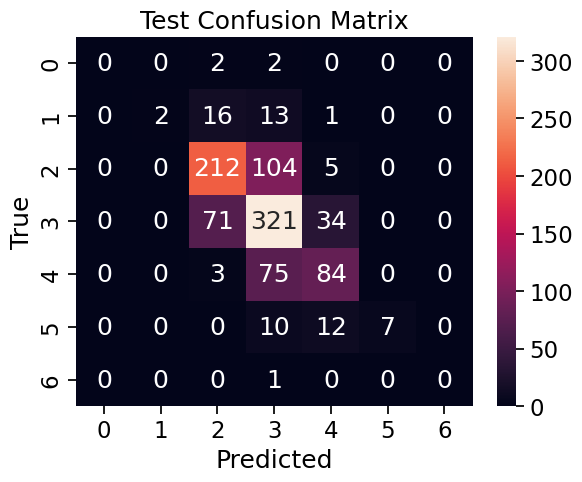

In [112]:
report_model_performance(pipe_knn, X_train, X_valid, X_test, y_train["quality"], y_valid["quality"], y_test["quality"])

In [113]:
save_model(pipe_knn, "knn")

## LVQ

In [118]:
from skopt.space import Integer, Categorical

cv = StratifiedShuffleSplit(n_splits=5, test_size=0.2, random_state=random_state)
lvq = GLVQ(random_state=random_state)
scoring = {
    "Accuracy": "accuracy", "ROC-AUC": "roc_auc_ovr",
    "Precision": "precision_macro", "Recall": "recall_macro", "F1": "f1_macro",
}
lvq_opt = BayesSearchCV(
    lvq,
    {
        "prototype_n_per_class": (1,100),
        "distance_type": ["euclidean", "squared-euclidean"],
    },
    n_iter=4,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_lvq = Pipeline([("scaler", scaler_lvq), ("lvq", lvq_opt)])

In [119]:
pipe_lvq.fit(X_train, y_train["quality"])

Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits


Pipeline(steps=[('scaler', MinMaxScaler()),
                ('lvq',
                 BayesSearchCV(cv=StratifiedShuffleSplit(n_splits=5, random_state=42, test_size=0.2,
            train_size=None),
                               estimator=GLVQ(random_state=42), n_iter=4,
                               n_jobs=-1, random_state=42, refit='Accuracy',
                               scoring={'Accuracy': 'accuracy',
                                        'F1': 'f1_macro',
                                        'Precision': 'precision_macro',
                                        'ROC-AUC': 'roc_auc_ovr',
                                        'Recall': 'recall_macro'},
                               search_spaces={'distance_type': ['euclidean',
                                                                'squared-euclidean'],
                                              'prototype_n_per_class': (1,
                                                                        100)},
                               verbose=1))])

Best parameters: OrderedDict([('distance_type', 'euclidean'), ('prototype_n_per_class', 73)])
Cross Validation accuracy Array: [0.54175824 0.53406593 0.53186813 0.55164835 0.55604396]
Validation accuracy: 0.54308 ± 0.01317
Cross Validation precision Array: [0.2766414  0.34291591 0.2756916  0.29679062 0.30050511]
Validation precision: 0.29851 ± 0.03388
Cross Validation recall Array: [0.24689286 0.27975939 0.24447354 0.26622289 0.26139409]
Validation recall: 0.25975 ± 0.01803
Cross Validation f1 Array: [0.24827484 0.29324218 0.24783124 0.27394328 0.26685942]
Validation f1: 0.26603 ± 0.02364
Cross Validation roc Array: [0.70826673 0.65927581 0.70292424 0.72559113 0.66929545]
Validation roc: 0.69307 ± 0.03453

===> Training performance
              precision    recall  f1-score   support

           3    0.80000   0.19048   0.30769        21
           4    0.59375   0.12500   0.20652       152
           5    0.60538   0.72193   0.65854      1496
           6    0.61074   0.63627   0.623

c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` param

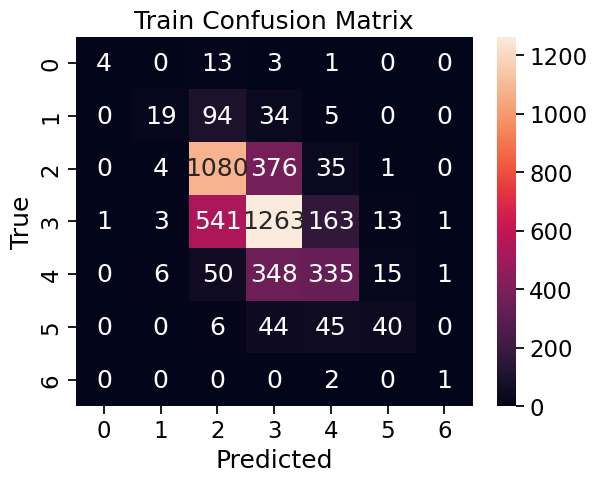

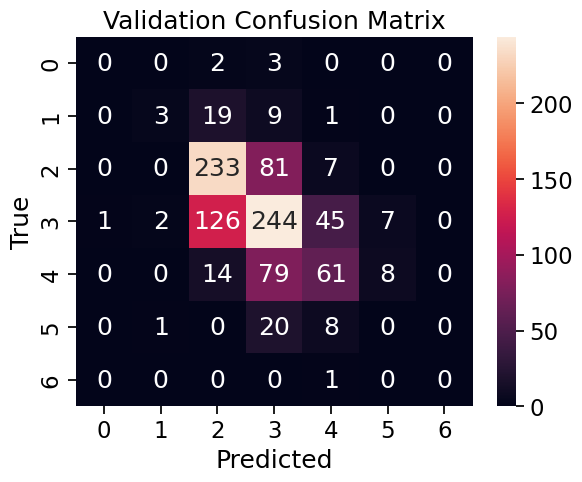

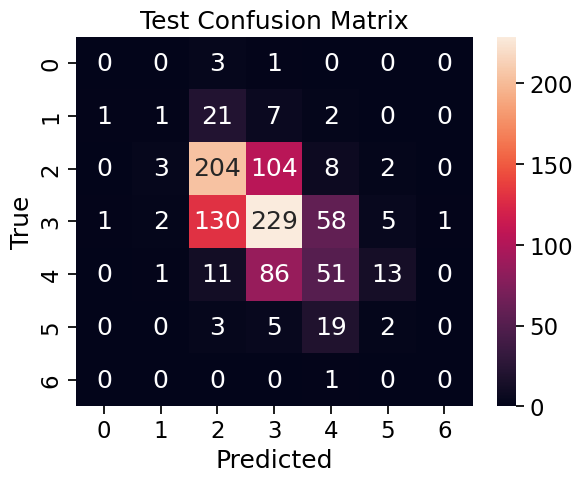

In [120]:
report_model_performance(pipe_lvq, X_train, X_valid, X_test, y_train["quality"], y_valid["quality"], y_test["quality"])

In [121]:
save_model(pipe_lvq, "lvq")

## Decision Tree 

In [122]:
cv = StratifiedShuffleSplit(n_splits=50, test_size=0.2, random_state=random_state)
dt = DecisionTreeClassifier(random_state=random_state)
scoring = {
    "Accuracy": "accuracy", "ROC-AUC": "roc_auc_ovr",
    "Precision": "precision_macro", "Recall": "recall_macro", "F1": "f1_macro",
}
dt_opt = BayesSearchCV(
    dt,
    {
        "criterion": ["gini", "entropy"],
        "splitter": ["best", "random"],
        "max_depth": (1, 100),
        "min_samples_split": (2, 100),
        "min_samples_leaf": (1, 100),
    },
    n_iter=25,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_dt = Pipeline([("scaler", scaler_dt), ("dt", dt_opt)])

In [123]:
pipe_dt.fit(X_train, y_train["quality"])

Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for eac

Pipeline(steps=[('scaler', MinMaxScaler()),
                ('dt',
                 BayesSearchCV(cv=StratifiedShuffleSplit(n_splits=50, random_state=42, test_size=0.2,
            train_size=None),
                               estimator=DecisionTreeClassifier(random_state=42),
                               n_iter=25, n_jobs=-1, random_state=42,
                               refit='Accuracy',
                               scoring={'Accuracy': 'accuracy',
                                        'F1': 'f1_macro',
                                        'Precision': 'precision_macro',
                                        'ROC-AUC': 'roc_auc_ovr',
                                        'Recall': 'recall_macro'},
                               search_spaces={'criterion': ['gini', 'entropy'],
                                              'max_depth': (1, 100),
                                              'min_samples_leaf': (1, 100),
                                              'min_samples_split': (2, 100),
                                              'splitter': ['best', 'random']},
                               verbose=1))])

In [ ]:
save_model(pipe_dt, "dt")

Best parameters: OrderedDict([('criterion', 'gini'), ('max_depth', 67), ('min_samples_leaf', 80), ('min_samples_split', 68), ('splitter', 'best')])
Cross Validation accuracy Array: [0.55714286 0.51868132 0.54395604 0.55494505 0.55714286 0.51208791
 0.54175824 0.53846154 0.51978022 0.54395604 0.53736264 0.50549451
 0.54725275 0.53626374 0.53296703 0.53516484 0.52857143 0.53516484
 0.53186813 0.55384615 0.53406593 0.52527473 0.54725275 0.54065934
 0.54175824 0.54835165 0.53736264 0.55054945 0.53626374 0.53956044
 0.51978022 0.54835165 0.56043956 0.53516484 0.52307692 0.53516484
 0.54725275 0.53736264 0.53076923 0.56373626 0.55384615 0.54615385
 0.54175824 0.50989011 0.54065934 0.53846154 0.53626374 0.55164835
 0.53406593 0.53516484]
Validation accuracy: 0.53844 ± 0.00361
Cross Validation precision Array: [0.23438606 0.21415743 0.22785548 0.21929108 0.22767378 0.20603953
 0.21803127 0.22074216 0.20629769 0.22790436 0.22260707 0.20892857
 0.2245139  0.21691835 0.21562903 0.21581787 0.21994

c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` param

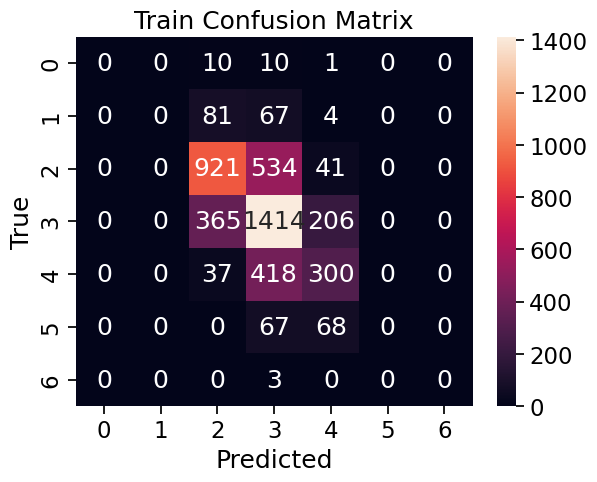

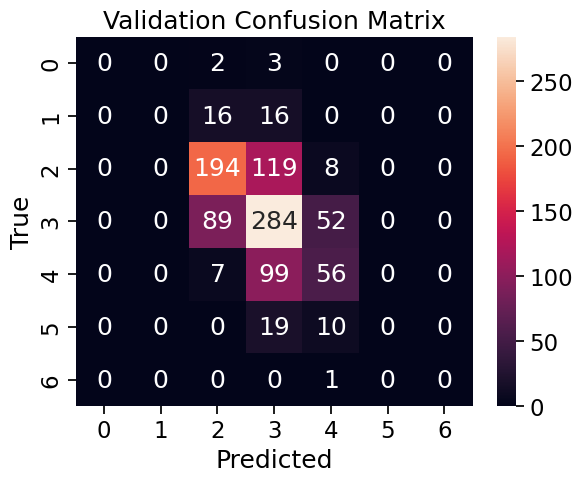

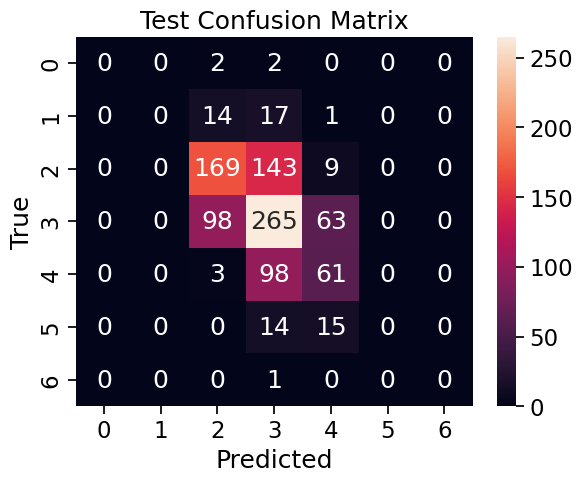

In [125]:
report_model_performance(pipe_dt, X_train, X_valid, X_test, y_train["quality"], y_valid["quality"], y_test["quality"])

## Random Forest

In [127]:
cv = StratifiedShuffleSplit(n_splits=50, test_size=0.2, random_state=random_state)
rf = RandomForestClassifier(random_state=random_state)
scoring = {
    "Accuracy": "accuracy", "ROC-AUC": "roc_auc_ovr",
    "Precision": "precision_macro", "Recall": "recall_macro", "F1": "f1_macro",
}
rf_opt = BayesSearchCV(
    rf,
    {
        "n_estimators": (1, 1000),
        "criterion": ["gini", "entropy"],
        "max_depth": (1, 100),
        "min_samples_split": (2, 100),
        "min_samples_leaf": (1, 100),
        "max_features": Categorical([None, "sqrt", "log2"]),
    },
    n_iter=25,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_rf = Pipeline([("scaler", scaler_rf), ("rfr", rf_opt)])

In [128]:
pipe_rf.fit(X_train, y_train["quality"])

Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for eac

Pipeline(steps=[('scaler', MinMaxScaler()),
                ('rfr',
                 BayesSearchCV(cv=StratifiedShuffleSplit(n_splits=50, random_state=42, test_size=0.2,
            train_size=None),
                               estimator=RandomForestClassifier(random_state=42),
                               n_iter=25, n_jobs=-1, random_state=42,
                               refit='Accuracy',
                               scoring={'Accuracy': 'accuracy',
                                        'F1': 'f1_macro',
                                        'Precision': 'precision_macro',
                                        'ROC-AUC': 'roc_auc_ovr',
                                        'Recall': 'recall_macro'},
                               search_spaces={'criterion': ['gini', 'entropy'],
                                              'max_depth': (1, 100),
                                              'max_features': Categorical(categories=(None, 'sqrt', 'log2'), prior=None),
                                              'min_samples_leaf': (1, 100),
                                              'min_samples_split': (2, 100),
                                              'n_estimators': (1, 1000)},
                               verbose=1))])

In [133]:
save_model(pipe_rf, "rf")

Best parameters: OrderedDict([('criterion', 'entropy'), ('max_depth', 100), ('max_features', 'sqrt'), ('min_samples_leaf', 1), ('min_samples_split', 2), ('n_estimators', 1000)])
Cross Validation accuracy Array: [0.65274725 0.64065934 0.67362637 0.66043956 0.65604396 0.64835165
 0.66483516 0.63516484 0.64505495 0.67472527 0.64615385 0.64725275
 0.66703297 0.65384615 0.65054945 0.63626374 0.65714286 0.65714286
 0.66703297 0.67252747 0.63846154 0.65714286 0.65934066 0.69340659
 0.66153846 0.64615385 0.65934066 0.65164835 0.64725275 0.64395604
 0.65934066 0.65054945 0.65714286 0.63846154 0.65824176 0.65274725
 0.69010989 0.67362637 0.66043956 0.65714286 0.62967033 0.65604396
 0.65604396 0.64285714 0.64725275 0.64505495 0.65494505 0.65494505
 0.64065934 0.63076923]
Validation accuracy: 0.65442 ± 0.00374
Cross Validation precision Array: [0.52267227 0.46113334 0.56408732 0.48705899 0.52020273 0.50221515
 0.56039853 0.51823688 0.50515758 0.46665502 0.48415643 0.50659436
 0.49281676 0.4948105 

c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` param

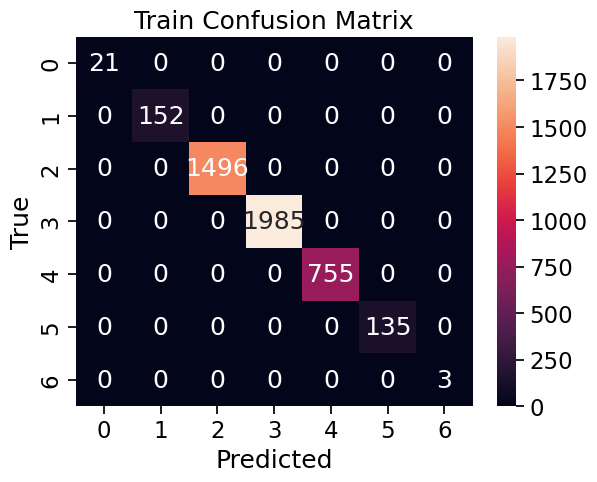

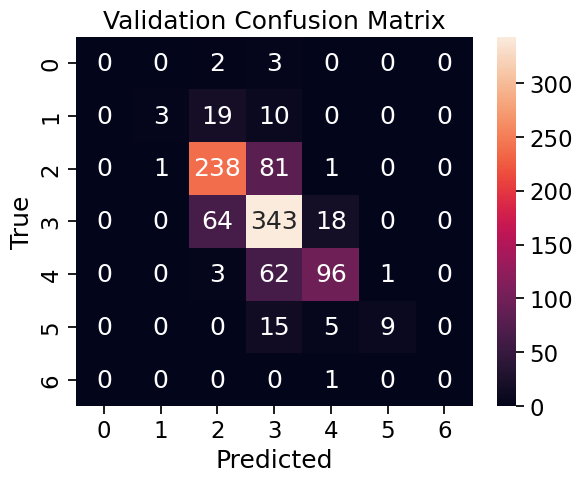

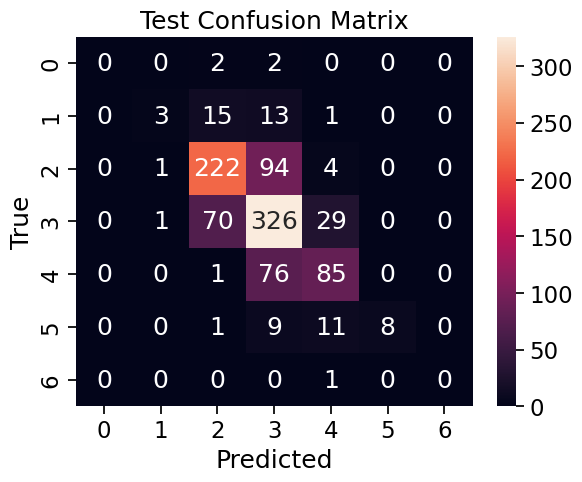

In [134]:
report_model_performance(pipe_rf, X_train, X_valid, X_test, y_train["quality"], y_valid["quality"], y_test["quality"])

## AdaBoost

In [135]:
cv = StratifiedShuffleSplit(n_splits=50, test_size=0.2, random_state=random_state)
ada = AdaBoostClassifier(random_state=random_state)
scoring = {
    "Accuracy": "accuracy", "ROC-AUC": "roc_auc_ovr",
    "Precision": "precision_macro", "Recall": "recall_macro", "F1": "f1_macro",
}
ada_opt = BayesSearchCV(
    ada,
    {
        "n_estimators": (1, 1000),
        "learning_rate": (0.01, 1),
        "algorithm": ["SAMME", "SAMME.R"],
    },
    n_iter=25,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_opt = Pipeline([("scaler", scaler_ada), ("ada", ada_opt)])

In [136]:
pipe_opt.fit(X_train, y_train["quality"])

Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits


c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\skopt\optimizer\optimizer.py:517: UserWarning: The objective has been evaluated at point ['SAMME', 0.01, 1000] before, using random point ['SAMME', 0.1285822872937136, 647]
  warnings.warn(


Fitting 50 folds for each of 1 candidates, totalling 50 fits


c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\skopt\optimizer\optimizer.py:517: UserWarning: The objective has been evaluated at point ['SAMME', 0.01, 1000] before, using random point ['SAMME.R', 0.5573256614319847, 681]
  warnings.warn(


Fitting 50 folds for each of 1 candidates, totalling 50 fits


c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\skopt\optimizer\optimizer.py:517: UserWarning: The objective has been evaluated at point ['SAMME', 0.01, 1000] before, using random point ['SAMME', 0.9855036418326474, 66]
  warnings.warn(


... (10 outputs left out)

Fitting 50 folds for each of 1 candidates, totalling 50 fits


c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\skopt\optimizer\optimizer.py:517: UserWarning: The objective has been evaluated at point ['SAMME', 0.01, 1000] before, using random point ['SAMME', 0.7253586026350268, 642]
  warnings.warn(


Fitting 50 folds for each of 1 candidates, totalling 50 fits


Pipeline(steps=[('scaler', MinMaxScaler()),
                ('ada',
                 BayesSearchCV(cv=StratifiedShuffleSplit(n_splits=50, random_state=42, test_size=0.2,
            train_size=None),
                               estimator=AdaBoostClassifier(random_state=42),
                               n_iter=25, n_jobs=-1, random_state=42,
                               refit='Accuracy',
                               scoring={'Accuracy': 'accuracy',
                                        'F1': 'f1_macro',
                                        'Precision': 'precision_macro',
                                        'ROC-AUC': 'roc_auc_ovr',
                                        'Recall': 'recall_macro'},
                               search_spaces={'algorithm': ['SAMME', 'SAMME.R'],
                                              'learning_rate': (0.01, 1),
                                              'n_estimators': (1, 1000)},
                               verbose=1))])

In [137]:
save_model(pipe_opt, "ada")

Best parameters: OrderedDict([('algorithm', 'SAMME'), ('learning_rate', 0.010973185968283172), ('n_estimators', 926)])
Cross Validation accuracy Array: [0.53626374 0.51538462 0.51318681 0.51758242 0.52417582 0.52857143
 0.51758242 0.4989011  0.51428571 0.54285714 0.53956044 0.52527473
 0.52747253 0.52417582 0.50989011 0.54065934 0.51978022 0.5043956
 0.52197802 0.52197802 0.5032967  0.4989011  0.53076923 0.52747253
 0.52857143 0.52087912 0.48791209 0.52527473 0.48351648 0.51648352
 0.54505495 0.51868132 0.53626374 0.51978022 0.51648352 0.51208791
 0.54835165 0.49340659 0.52747253 0.52197802 0.52087912 0.52087912
 0.53186813 0.51978022 0.52527473 0.53406593 0.55054945 0.52527473
 0.52307692 0.53076923]
Validation accuracy: 0.52178 ± 0.00404
Cross Validation precision Array: [0.21816911 0.2090767  0.21200288 0.20230666 0.20914612 0.21627063
 0.21307591 0.20292821 0.20499796 0.2190388  0.22496961 0.21397243
 0.21692859 0.21321004 0.18676196 0.22034339 0.21561092 0.20791737
 0.21358024 0.2

c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` param

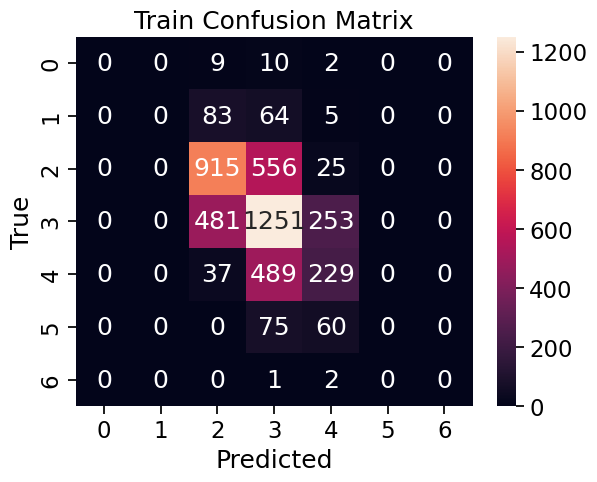

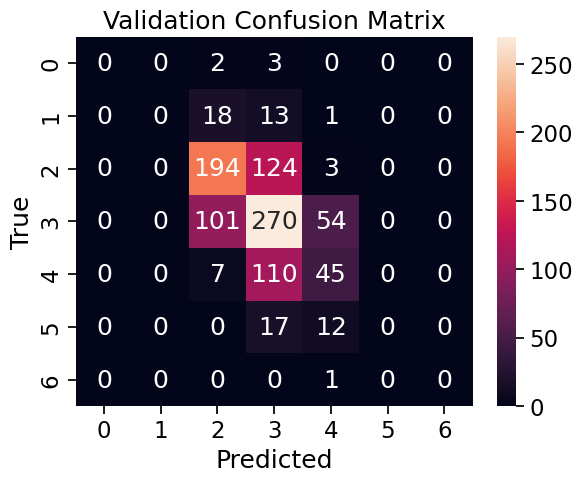

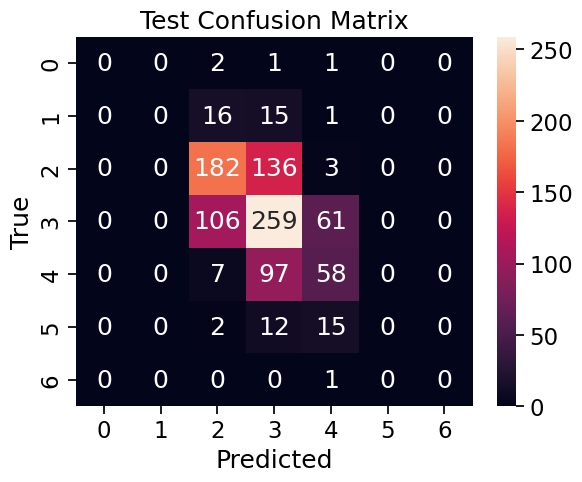

In [138]:
report_model_performance(pipe_opt, X_train, X_valid, X_test, y_train["quality"], y_valid["quality"], y_test["quality"])

## MLP

In [147]:
cv = StratifiedShuffleSplit(n_splits=5, test_size=0.2, random_state=random_state)
mlp = MLPClassifier(random_state=random_state, max_iter=1000)
scoring = {
    "Accuracy": "accuracy", "ROC-AUC": "roc_auc_ovr",
    "Precision": "precision_macro", "Recall": "recall_macro", "F1": "f1_macro",
}
mlp_opt = RandomizedSearchCV(
    mlp,
    {
        "hidden_layer_sizes": [(5,), (10,), (5, 10), (10, 5), (10, 10)],
        "activation": ["identity", "logistic", "tanh", "relu"],
        "solver": ["lbfgs", "sgd", "adam"],
        "alpha": np.arange(0, 100),
        "learning_rate": ["constant", "invscaling", "adaptive"],
    },
    n_iter=4,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_mlp = Pipeline([("scaler", scaler_mlp), ("mlp", mlp_opt)])

In [149]:
pipe_mlp.fit(X_train, y_train["quality"])

Fitting 5 folds for each of 4 candidates, totalling 20 fits


Pipeline(steps=[('scaler', MinMaxScaler()),
                ('mlp',
                 RandomizedSearchCV(cv=StratifiedShuffleSplit(n_splits=5, random_state=42, test_size=0.2,
            train_size=None),
                                    estimator=MLPClassifier(max_iter=1000,
                                                            random_state=42),
                                    n_iter=4, n_jobs=-1,
                                    param_distributions={'activation': ['identity',
                                                                        'logistic',
                                                                        'tanh',
                                                                        'relu'],
                                                         'alpha': array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15...
       85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99]),
                                                         'hidden_layer_sizes': [(5,),
                                                                                (10,),
                                                                                (5,
                                                                                 10),
                                                                                (10,
                                                                                 5),
                                                                                (10,
                                                                                 10)],
                                                         'learning_rate': ['constant',
                                                                           'invscaling',
                                                                           'adaptive'],
                                                         'solver': ['lbfgs',
                                                                    'sgd',
                                                                    'adam']},
                                    random_state=42, refit='Accuracy',
                                    scoring={'Accuracy': 'accuracy',
                                             'F1': 'f1_macro',
                                             'Precision': 'precision_macro',
                                             'ROC-AUC': 'roc_auc_ovr',
                                             'Recall': 'recall_macro'},
                                    verbose=1))])

Best parameters: {'solver': 'lbfgs', 'learning_rate': 'invscaling', 'hidden_layer_sizes': (10, 10), 'alpha': 65, 'activation': 'tanh'}
Cross Validation accuracy Array: [0.54505495 0.52087912 0.51428571 0.53516484 0.53296703]
Validation accuracy: 0.52967 ± 0.01510
Cross Validation precision Array: [0.30206161 0.24521884 0.29275202 0.15534456 0.19244124]
Validation precision: 0.23756 ± 0.07868
Cross Validation recall Array: [0.20171245 0.19378551 0.19010365 0.1977697  0.1963389 ]
Validation recall: 0.19594 ± 0.00540
Cross Validation f1 Array: [0.17830254 0.17405444 0.16800465 0.17322397 0.17407525]
Validation f1: 0.17353 ± 0.00456
Cross Validation roc Array: [0.6196035  0.65825955 0.64480121 0.58999812 0.67645022]
Validation roc: 0.63782 ± 0.04200

===> Training performance
              precision    recall  f1-score   support

           3    0.00000   0.00000   0.00000        21
           4    0.00000   0.00000   0.00000       152
           5    0.57375   0.61364   0.59302      1496


c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` param

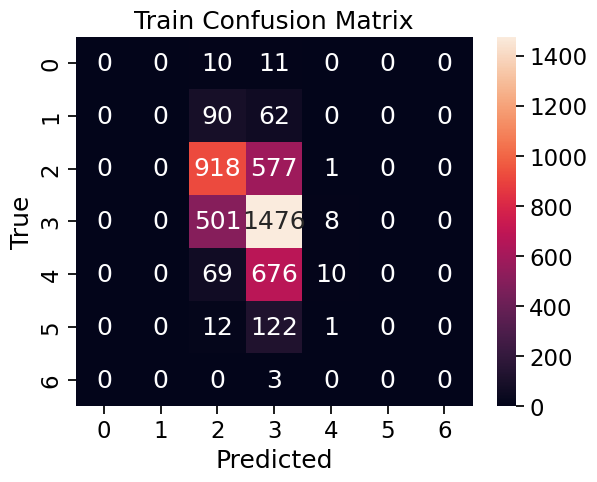

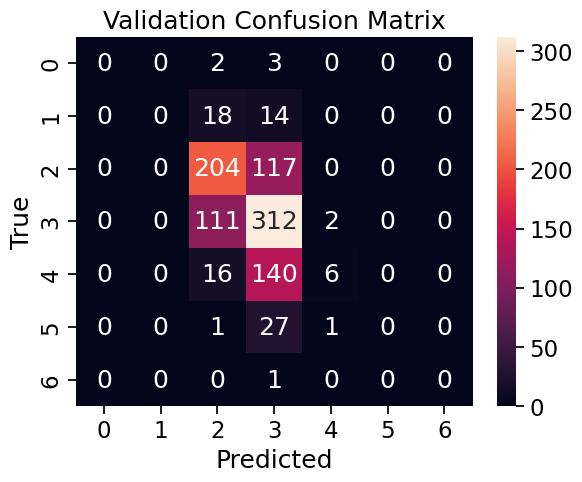

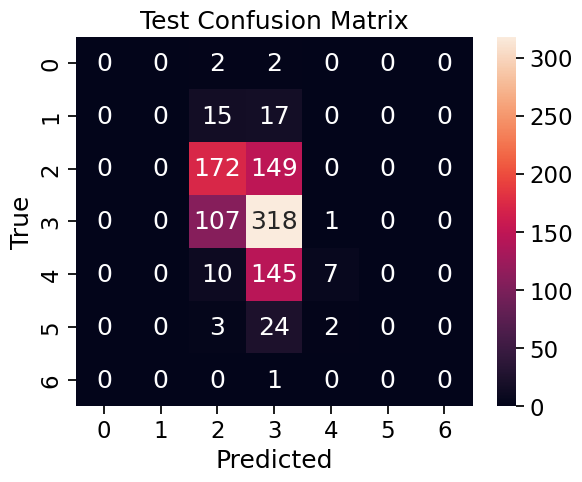

In [150]:
report_model_performance(pipe_mlp, X_train, X_valid, X_test, y_train["quality"], y_valid["quality"], y_test["quality"])

In [151]:
save_model(pipe_mlp, "mlp")

## ELM